# Crude-to-pump pass-through and gasoline's contribution to inflation

Phase 3 of the project. Question 1: when crude oil moves 1 c/L (in CAD), how much of that reaches the Toronto pump, and how fast? Do prices rise faster than they fall ("rockets and feathers")? Question 2: how much of Canadian CPI inflation since 2015 came from gasoline?

All code lives in `drivecost/passthrough.py` and `drivecost/inflation.py`; this notebook runs it and shows the results.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
from drivecost import passthrough, inflation
from drivecost.data import monthly_panel
pd.set_option("display.float_format", "{:.3f}".format)
monthly_panel().loc["2015-01":, ["pump_cpl", "tax_cpl", "pump_ex_tax_cpl", "crude_cpl", "wholesale_cpl"]].describe()

,pump_cpl,tax_cpl,pump_ex_tax_cpl,crude_cpl,wholesale_cpl
count,141.000,141.000,141.000,141.000,141.000
mean,130.799,28.537,87.214,53.255,71.167
std,25.857,5.180,22.076,15.426,22.489
min,79.100,19.000,38.670,14.634,22.022
25%,107.800,24.700,68.663,41.492,54.805
50%,127.300,29.120,83.889,52.032,68.123
75%,148.800,33.310,101.443,63.738,82.958
max,205.900,36.610,146.462,92.555,138.175


## 1. Symmetric distributed-lag model

$\Delta Pump_t = a + \sum_{k=0}^{3} b_k\,\Delta Crude_{t-k} + c\,\Delta Tax_t + e_t$, monthly, January 2015 onward, Newey-West standard errors.

With 13% HST, *full* pass-through of a 1 c/L crude move is 1.13 c/L at the pump.

In [2]:
r = passthrough.estimate("crude_cpl", lags=3)
print(r.symmetric.summary().tables[1])
r.cum_sym

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2122      0.318      0.667      0.505      -0.412       0.836
dx_l0          1.2570      0.099     12.710      0.000       1.063       1.451
dx_l1          0.0488      0.092      0.532      0.595      -0.131       0.229
dx_l2          0.0967      0.098      0.987      0.324      -0.095       0.289
dx_l3          0.0413      0.085      0.488      0.625      -0.124       0.207
dtax           0.9161      0.212      4.311      0.000       0.500       1.333


,month,cum,lo,hi,se
0,0,1.257,1.063,1.451,0.099
1,1,1.306,1.088,1.524,0.111
2,2,1.402,1.131,1.674,0.138
3,3,1.444,1.110,1.777,0.170


## 2. Rises vs falls

The crude change is split into rises and falls, each with its own lags. The Wald tests check whether the response is the same in both directions.

In [3]:
print(r.asymmetric.summary().tables[1])
pd.Series({k: v for k, v in r.tests.items() if k.startswith("wald")})

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.2614      0.542     -0.482      0.630      -1.323       0.801
dxpos_l0       1.0643      0.105     10.164      0.000       0.859       1.270
dxpos_l1       0.3434      0.127      2.698      0.007       0.094       0.593
dxpos_l2       0.0011      0.170      0.006      0.995      -0.332       0.334
dxpos_l3       0.1777      0.139      1.281      0.200      -0.094       0.450
dxneg_l0       1.5346      0.199      7.723      0.000       1.145       1.924
dxneg_l1      -0.3325      0.183     -1.817      0.069      -0.691       0.026
dxneg_l2       0.2813      0.147      1.918      0.055      -0.006       0.569
dxneg_l3      -0.1403      0.118     -1.184      0.236      -0.372       0.092
dtax           0.8340      0.197      4.227      0.000       0.447       1.221


wald_cum_pos_eq_neg_F       0.757
wald_cum_pos_eq_neg_p       0.384
wald_contemp_pos_eq_neg_F   3.942
wald_contemp_pos_eq_neg_p   0.047
wald_ecm_adjust_eq_F        4.824
wald_ecm_adjust_eq_p        0.028
dtype: float64

## 3. Asymmetric error-correction model

Long run: $PumpExTax_t = \alpha + \gamma\,Crude_t + u_t$. In the short run, the lagged gap $u_{t-1}$ enters separately when the pump is above its long-run level (fat margins, $u^+$) and when it is below (squeezed margins, $u^-$).

In [4]:
print(r.ecm.params[["ect_pos", "ect_neg"]])
print(f"half-life when margins are fat:      {r.tests['half_life_months_pos']:.1f} months")
print(f"half-life when margins are squeezed: {r.tests['half_life_months_neg']:.1f} months")
print(f"test that both speeds are equal: p = {r.tests['wald_ecm_adjust_eq_p']:.3f}")

ect_pos   -0.061
ect_neg   -0.485
dtype: float64
half-life when margins are fat:      11.0 months
half-life when margins are squeezed: 1.0 months
test that both speeds are equal: p = 0.028


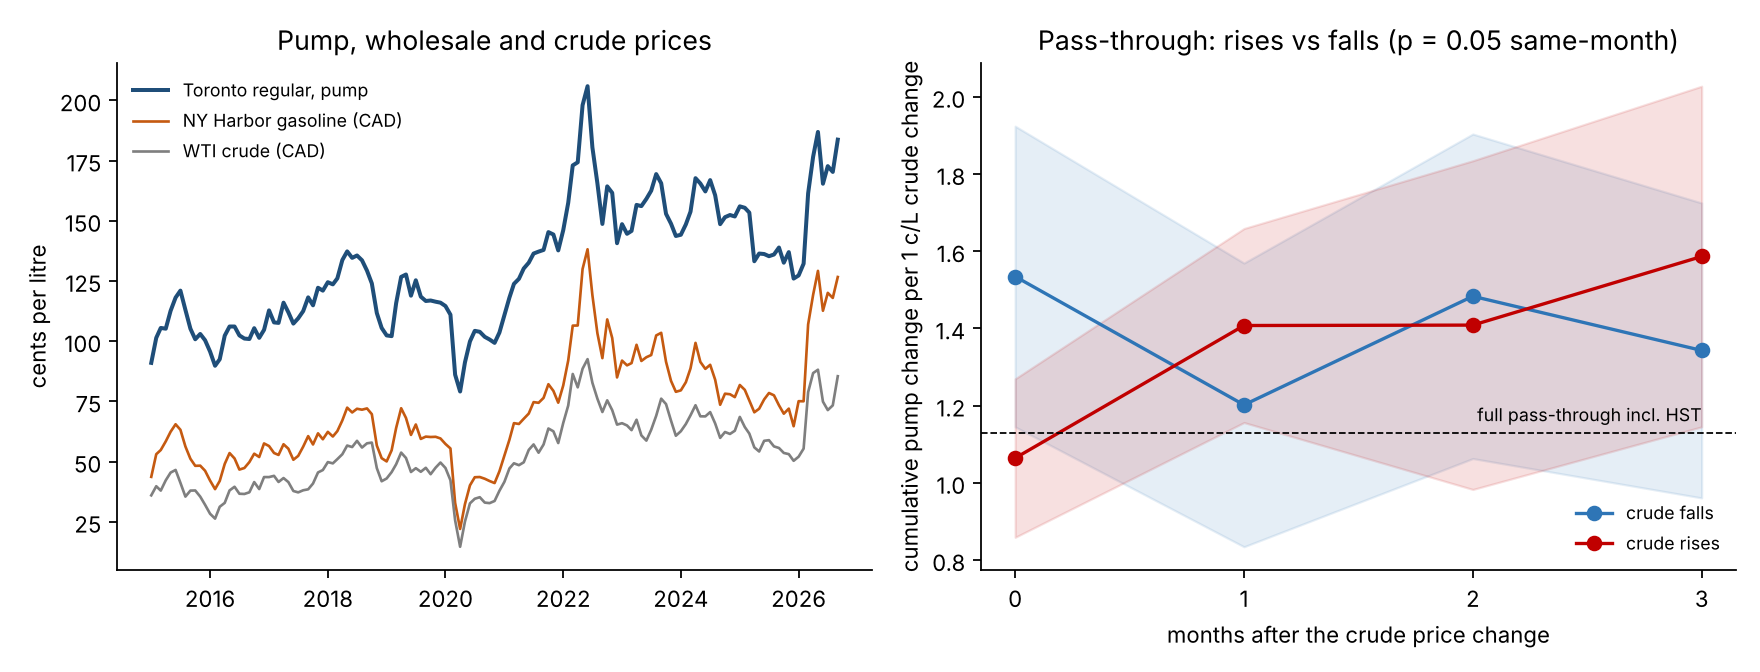

In [5]:
display(Image(str(passthrough.plot(r))))

## 4. Wholesale gasoline instead of crude

Wholesale gasoline (NY Harbor, in CAD) separates the refining step from the retail step.

In [6]:
rw = passthrough.estimate("wholesale_cpl", lags=3)
pd.DataFrame({"crude": r.tests, "wholesale gasoline": rw.tests}).loc[
    ["cum_symmetric", "share_passed_through", "share_in_first_month", "wald_contemp_pos_eq_neg_p",
     "wald_cum_pos_eq_neg_p", "half_life_months_pos", "half_life_months_neg", "wald_ecm_adjust_eq_p", "n_obs"]]

,crude,wholesale gasoline
cum_symmetric,1.444,1.103
share_passed_through,1.278,0.976
share_in_first_month,0.871,0.924
wald_contemp_pos_eq_neg_p,0.047,0.082
wald_cum_pos_eq_neg_p,0.384,0.456
half_life_months_pos,11.041,9.371
half_life_months_neg,1.045,1.364
wald_ecm_adjust_eq_p,0.028,0.033
n_obs,141,141


**Reading the results**

* Pass-through is fast: most of a crude move reaches the pump in the same month. Against crude, the cumulative effect is *above* 1.13 because refining margins (crack spreads) widen when crude rises. Against wholesale gasoline it is close to the full 1.13 (share ~ 1).
* There is no rockets-and-feathers pattern in the direct response to crude rises vs falls. If anything, falls show up more in the same month. With monthly data this test has little power, because most of the adjustment happens within the month.
* The asymmetry shows up in **margins**. When the pump is above its long-run level, the gap closes slowly (half-life ~ 10 months). When it is below, it closes within about a month. That is rockets and feathers in error-correction form, and it is significant at 5%.
* Limitation: StatCan prices are monthly averages. Weekly or daily station data (e.g. Kalibrate) would sharpen the timing results.

## 5. Gasoline's contribution to CPI inflation

In [7]:
a = inflation.annual_contribution()
a[["headline_pct", "gasoline_contribution_pp", "ex_gasoline_contribution_pp", "gasoline_yoy_pct"]]

,headline_pct,gasoline_contribution_pp,ex_gasoline_contribution_pp,gasoline_yoy_pct
year,,,,
2015,1.125,-0.771,1.896,-16.359
2016,1.430,-0.231,1.661,-5.688
2017,1.598,0.424,1.174,12.142
2018,2.268,0.446,1.823,12.872
2019,1.948,-0.237,2.186,-5.875
2020,0.722,-0.470,1.192,-13.117
2021,3.394,0.903,2.491,32.481
2022,6.798,1.039,5.759,29.011
2023,3.894,-0.307,4.201,-6.829


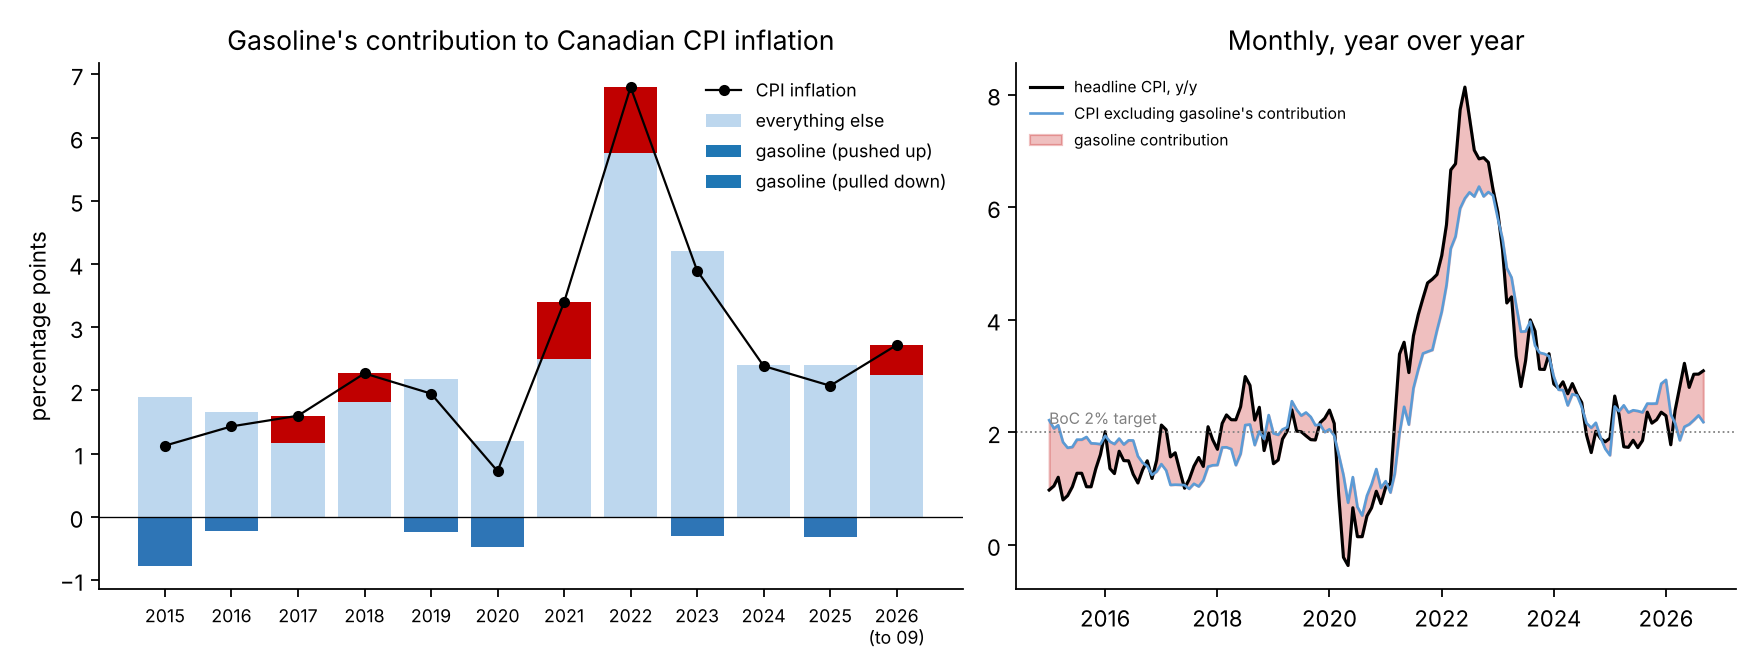

In [8]:
m = inflation.monthly_contribution()
display(Image(str(inflation.plot(a, m.loc["2015-01":]))))

Gasoline is only about 3-4% of the CPI basket, but its price swings are so large that it explains much of the year-to-year movement in headline inflation. It pulled 2015 and 2020 inflation down by about 0.5-0.8 points and pushed 2021-2022 up by about 1 point. In 2026 it is again adding about half a point.